In [1]:
!pip install -q ultralytics
import glob
resimler = sorted(glob.glob("/kaggle/input/**/*.jp*g", recursive=True) +
                  glob.glob("/kaggle/input/**/*.png", recursive=True))
print(len(resimler), "resim bulundu:")
for r in resimler: print(r)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.5 MB/s eta 0:00:00
4 resim bulundu:
/kaggle/input/datasets/hamzabilici/restoran-4-masa-resmi/Ekran grnts 2026-10-21 212526.png
/kaggle/input/datasets/hamzabilici/restoran-4-masa-resmi/Ekran grnts 2026-10-21 212721.png
/kaggle/input/datasets/hamzabilici/restoran-4-masa-resmi/Ekran grnts 2026-10-21 212733.png
/kaggle/input/datasets/hamzabilici/restoran-4-masa-resmi/Ekran grnts 2026-10-21 212756.png


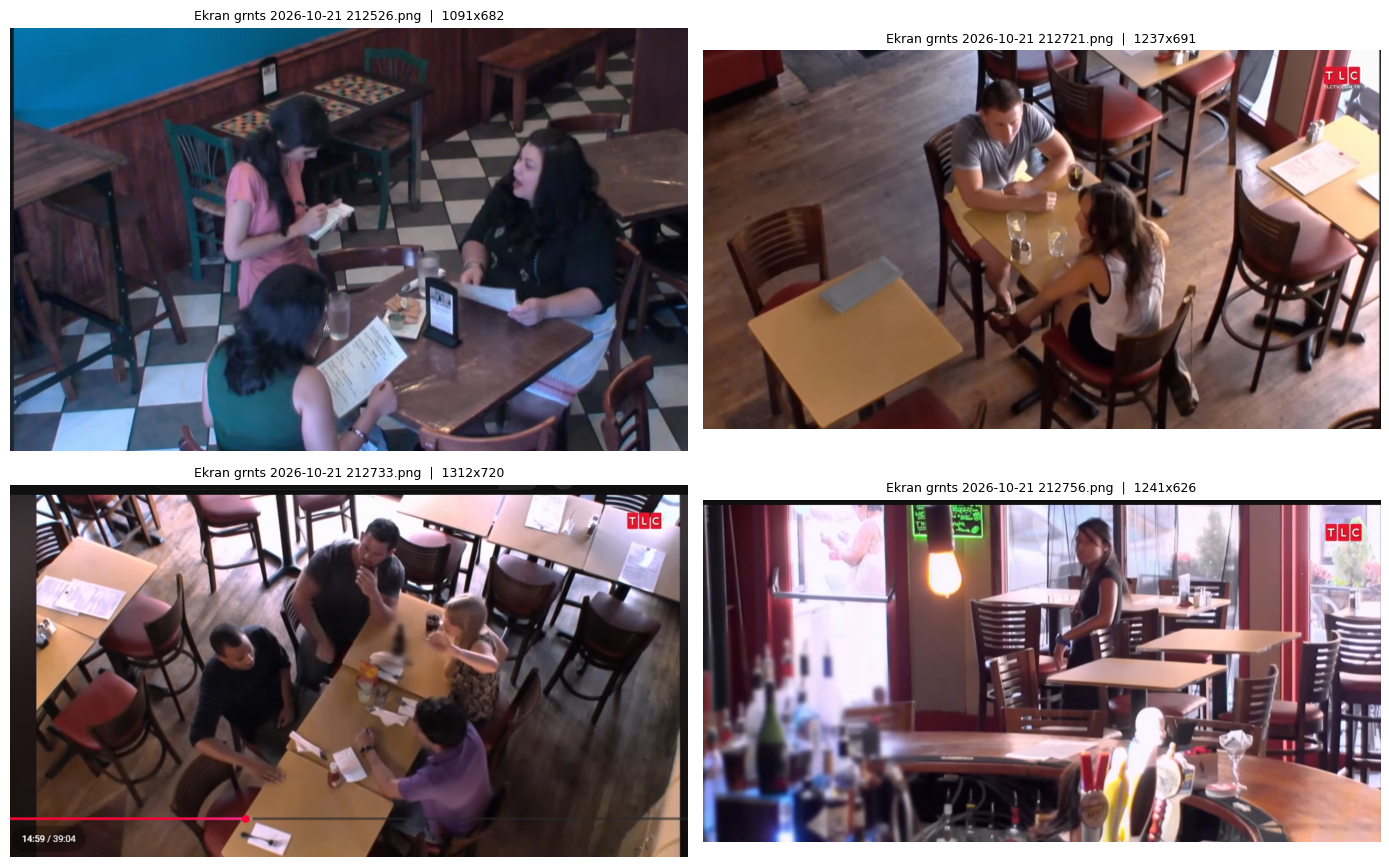

In [2]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, yol in zip(axes.ravel(), resimler):
    img = cv2.imread(yol)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{yol.split('/')[-1]}  |  {img.shape[1]}x{img.shape[0]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


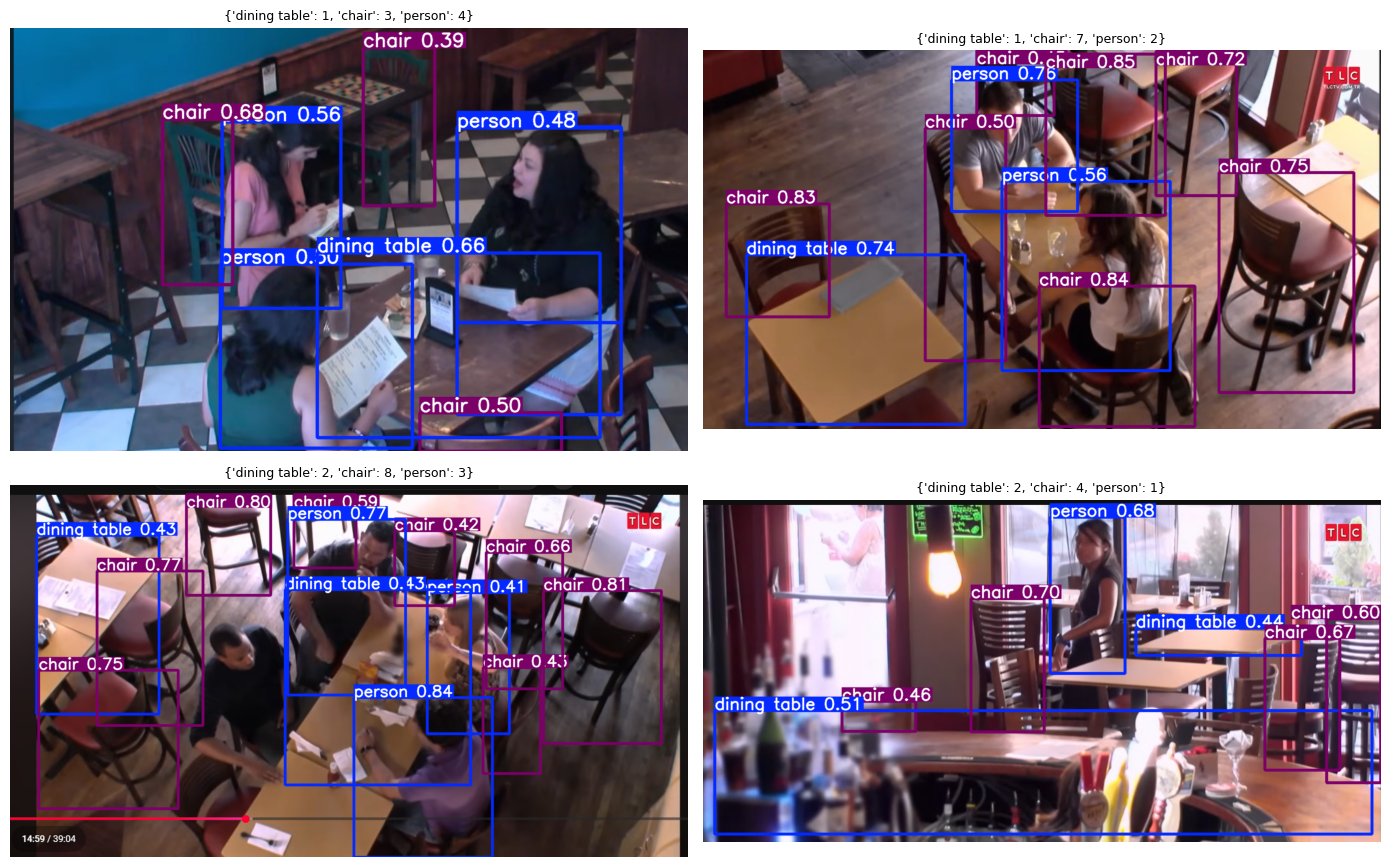

In [3]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")   # hazir COCO modeli
SINIFLAR = [0, 56, 60]       # 0=person, 56=chair, 60=dining table

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, yol in zip(axes.ravel(), resimler):
    r = model(yol, classes=SINIFLAR, conf=0.38, verbose=False)[0]
    isimler = [model.names[int(c)] for c in r.boxes.cls]
    ozet = {n: isimler.count(n) for n in set(isimler)}
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(str(ozet), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

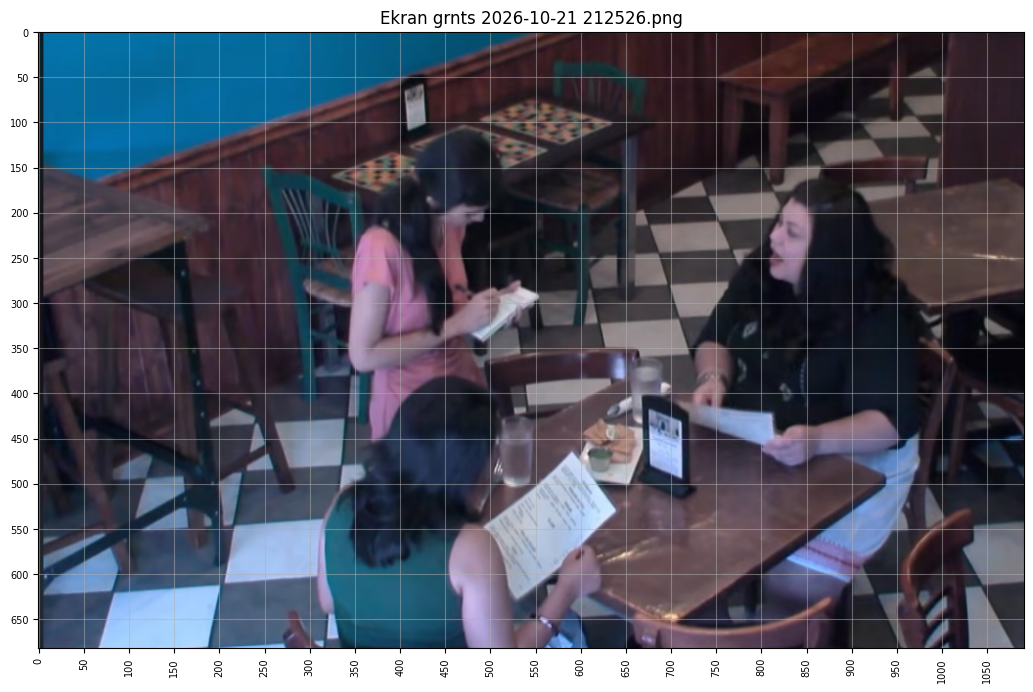

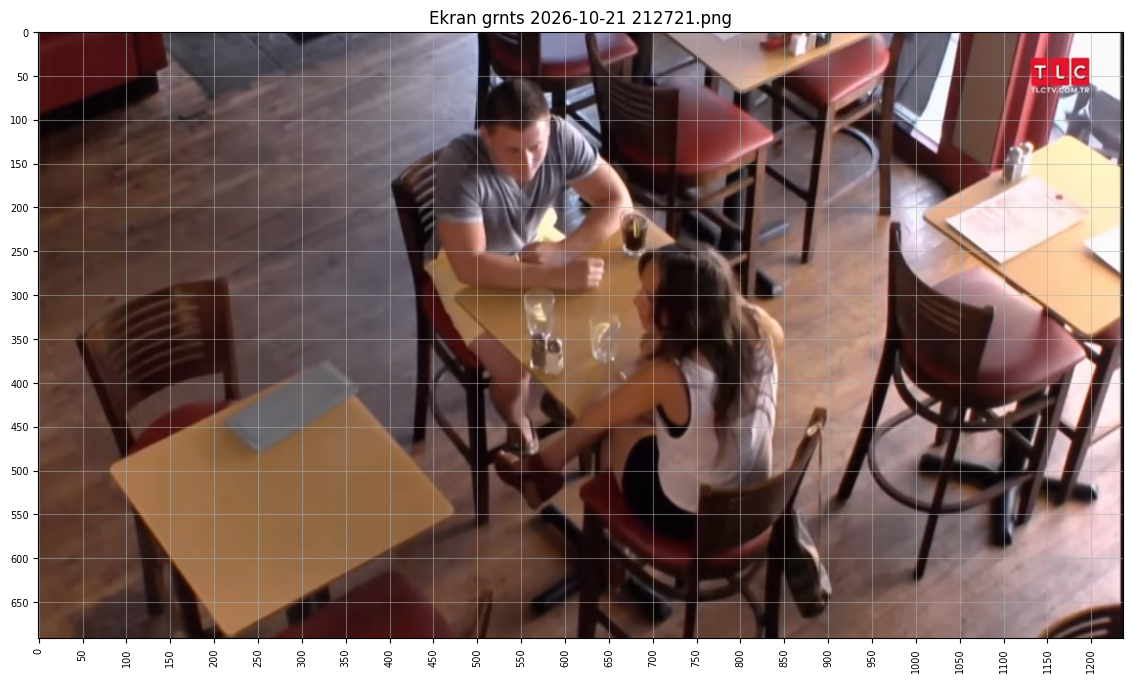

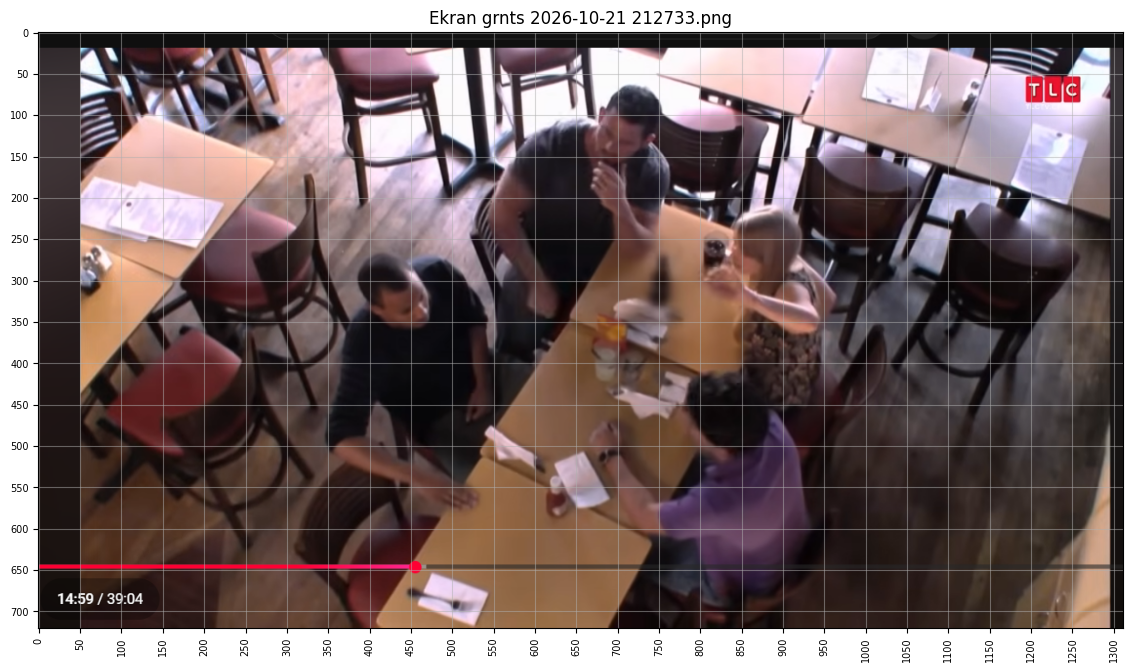

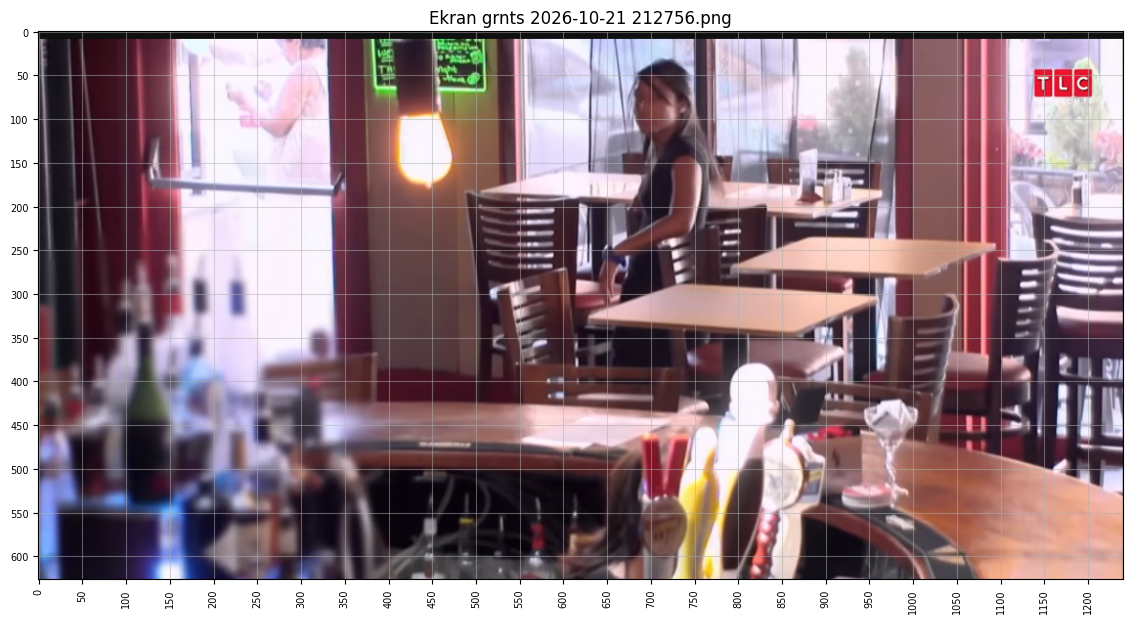

In [4]:
for yol in resimler:
    img = cv2.imread(yol)
    h, w = img.shape[:2]
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.xticks(range(0, w, 50), rotation=90, fontsize=7)
    plt.yticks(range(0, h, 50), fontsize=7)
    plt.grid(alpha=0.5)
    plt.title(yol.split('/')[-1])
    plt.show()

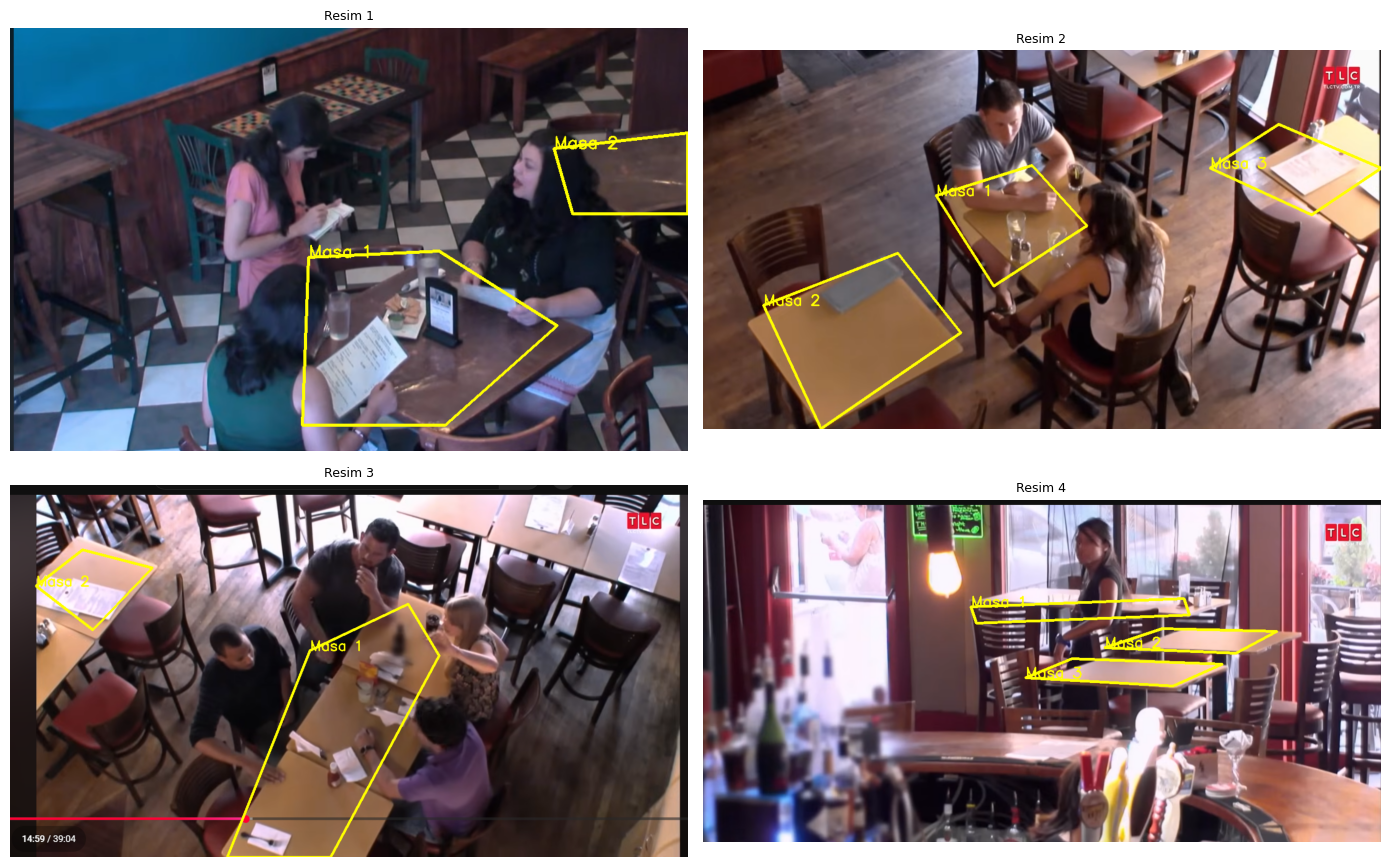

In [5]:
import numpy as np

# Her resim icin masa kose noktalari (x, y) - yaklasik, gerekirse duzelt
MASALAR = {
    0: {"Masa 1": [(480,370), (690,360), (880,480), (700,640), (470,640)],
        "Masa 2": [(875,195), (1090,170), (1090,300), (905,300)]},
    1: {"Masa 1": [(425,265), (600,210), (700,320), (530,430)],
        "Masa 2": [(110,465), (355,370), (470,515), (215,690)],
        "Masa 3": [(925,215), (1050,135), (1237,215), (1110,300)]},
    2: {"Masa 1": [(580,320), (770,230), (830,330), (620,720), (420,720)],
        "Masa 2": [(50,195), (140,125), (275,160), (160,280)]},
    3: {"Masa 1": [(490,195), (880,180), (890,210), (500,225)],
        "Masa 2": [(735,270), (840,235), (1050,240), (975,280)],
        "Masa 3": [(590,325), (675,290), (950,300), (860,340)]},
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, (ax, yol) in enumerate(zip(axes.ravel(), resimler)):
    img = cv2.imread(yol)
    for ad, noktalar in MASALAR[i].items():
        pts = np.array(noktalar, np.int32)
        cv2.polylines(img, [pts], isClosed=True, color=(0, 255, 255), thickness=3)
        cv2.putText(img, ad, tuple(pts[0]), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Resim {i+1}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()